# Lineare Regression „from scratch“

Begleitnotebook zu **Vorlesung 4: Lineare Regression**.

In diesem Notebook implementieren wir lineare Regression mit **Gradient Descent** selbst – ohne fertige ML-Bibliothek, nur mit NumPy. So sehen wir, was hinter `sklearn.linear_model.LinearRegression` steckt.

**Aufbau**

| Teil | Inhalt | Folien |
|---|---|---|
| 1 | Lineare Regression mit **einem** Feature: Modell, Kostenfunktion, Gradienten, Gradient Descent | 5–35 |
| 2 | Evaluation auf Testdaten, Lernrate, Vergleich mit sklearn | 33–39 |
| 3 | Lineare Regression mit **mehreren** Features, Feature Importance | 40–48 |

**Notation (wie auf den Folien)**

- $n$ = Anzahl der Datenpunkte, Index $i$
- $d$ = Anzahl der Features, Index $j$
- $w_0$ = Achsenabschnitt, $w_1, \dots, w_d$ = Gewichte der Features
- $\hat{y}_i = f(x_i)$ = Vorhersage des Modells für Datenpunkt $i$

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split

np.random.seed(42)  # reproduzierbare Ergebnisse

---
# Teil 1: Ein Feature

## 1.1 Daten

Wir nutzen den **Advertising-Datensatz**: Für 200 Märkte ist angegeben, wie viel Budget in TV-, Radio- und Zeitungswerbung geflossen ist (in T\$) und wie hoch der Umsatz war (`sales`, in Tsd. Einheiten).

Zunächst betrachten wir nur ein Feature: **TV-Budget → Umsatz** (wie im Einführungsbeispiel der Vorlesung).

In [2]:
df = pd.read_csv("../data/advertising.csv", index_col=0)
df.head()

,TV,radio,newspaper,sales
index,,,,
1,230.1,37.8,69.2,22.1
2,44.5,39.3,45.1,10.4
3,17.2,45.9,69.3,9.3
4,151.5,41.3,58.5,18.5
5,180.8,10.8,58.4,12.9


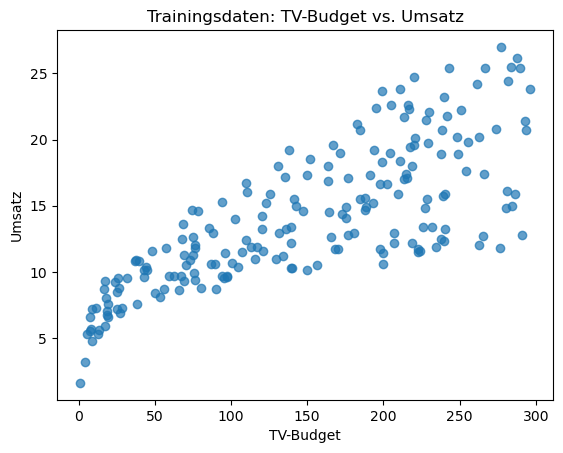

In [3]:
x = df["TV"].values      # Feature
y = df["sales"].values   # Label

plt.scatter(x, y, alpha=0.7)
plt.xlabel("TV-Budget")
plt.ylabel("Umsatz")
plt.title("Trainingsdaten: TV-Budget vs. Umsatz")
plt.show()

## 1.2 Modell und Kostenfunktion

Das Modell ist eine Gerade (Folie 10):

$$f(x) = w_0 + w_1 x$$

Wie gut eine Gerade zu den Daten passt, messen wir mit dem **Mean Squared Error** (Folie 16). Als Funktion der Gewichte heißt er **Kostenfunktion** (Folie 18):

$$J(w_0, w_1) = \frac{1}{n} \sum_{i=1}^{n} \bigl(y_i - (w_0 + w_1 x_i)\bigr)^2$$

In [4]:
def predict(w0, w1, x):
    # Vorhersage der Geraden f(x) = w0 + w1 * x
    return w0 + w1 * x

def mse(y, y_pred):
    # Mean Squared Error
    return np.mean((y - y_pred) ** 2)

Es gibt unendlich viele Geraden (Folie 11–14). Probieren wir drei von Hand aus – jede hat eine andere Kostenfunktion:

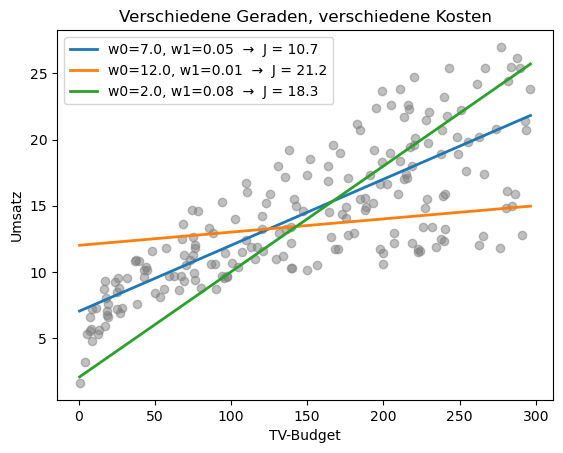

In [5]:
candidates = [(7.0, 0.05), (12.0, 0.01), (2.0, 0.08)]   # (w0, w1)
x_line = np.linspace(x.min(), x.max(), 100)

plt.scatter(x, y, alpha=0.5, color="gray")
for w0, w1 in candidates:
    J = mse(y, predict(w0, w1, x))
    plt.plot(x_line, predict(w0, w1, x_line), lw=2, label=f"w0={w0}, w1={w1}  →  J = {J:.1f}")
plt.xlabel("TV-Budget"); plt.ylabel("Umsatz")
plt.legend(); plt.title("Verschiedene Geraden, verschiedene Kosten")
plt.show()

**Frage:** Welche Gerade hat die kleinsten Kosten? Gibt es eine noch bessere?

Statt zu raten, suchen wir das Minimum von $J$ systematisch mit **Gradient Descent**.

## 1.3 Gradienten

Für Gradient Descent brauchen wir die partiellen Ableitungen von $J$ nach $w_0$ und $w_1$ (Folie 31):

$$\frac{\partial J}{\partial w_0} = \frac{1}{n}\sum_{i=1}^{n} -2\,\bigl(y_i - (w_0 + w_1 x_i)\bigr)
\qquad
\frac{\partial J}{\partial w_1} = \frac{1}{n}\sum_{i=1}^{n} -2\,x_i\bigl(y_i - (w_0 + w_1 x_i)\bigr)$$

Der Ausdruck $y_i - (w_0 + w_1 x_i)$ ist einfach der Fehler $e_i$ für Datenpunkt $i$.

In [6]:
def gradients(w0, w1, x, y):
    error = y - predict(w0, w1, x)       # e_i für alle Datenpunkte
    grad_w0 = -2 * np.mean(error)
    grad_w1 = -2 * np.mean(error * x)
    return grad_w0, grad_w1

## 1.4 Gradient Descent

Jetzt setzen wir den Pseudocode von Folie 32 um:

- Starte mit zufälligen Gewichten.
- Berechne in jeder Iteration beide Gradienten **mit den alten Gewichten** und aktualisiere dann beide Gewichte gleichzeitig:
  $w_j \leftarrow w_j - \alpha \frac{\partial J}{\partial w_j}$
- Höre auf, wenn sich die Gewichte kaum noch ändern.

Das Abbruchkriterium prüfen wir über die Größe des Gradienten: Die Änderung eines Gewichts ist $\alpha \cdot$ Gradient. Ist der Gradient fast null, ändern sich die Gewichte also kaum noch – genau das Kriterium von Folie 32.

Zusätzlich speichern wir in jeder Iteration die Kosten, um den Lernfortschritt später zu plotten.

In [7]:
class SimpleLinearRegressionGD:
    # Lineare Regression mit einem Feature, trainiert mit Gradient Descent

    def __init__(self, learning_rate=0.01, max_iterations=1000, tolerance=1e-6):
        self.learning_rate = learning_rate
        self.max_iterations = max_iterations
        self.tolerance = tolerance

    def fit(self, x, y):
        # 1. Zufällige Startwerte
        self.w0 = np.random.randn() * 0.01
        self.w1 = np.random.randn() * 0.01
        self.cost_history = []

        for iteration in range(self.max_iterations):
            self.cost_history.append(mse(y, predict(self.w0, self.w1, x)))

            # 2. Richtung des steilsten Abstiegs (beide Gradienten mit den alten Gewichten)
            grad_w0, grad_w1 = gradients(self.w0, self.w1, x, y)

            # 3. Schritt in diese Richtung (gleichzeitiges Update)
            self.w0 -= self.learning_rate * grad_w0
            self.w1 -= self.learning_rate * grad_w1

            # 4. Konvergenz: Gradienten (und damit Änderungen) sind fast null
            if abs(grad_w0) < self.tolerance and abs(grad_w1) < self.tolerance:
                break

        self.n_iterations = iteration + 1
        return self

    def predict(self, x):
        return predict(self.w0, self.w1, x)

## 1.5 Erster Versuch – und warum er scheitert

Trainieren wir das Modell direkt auf den Rohdaten:

In [8]:
with np.errstate(over="ignore", invalid="ignore"):
    model = SimpleLinearRegressionGD(learning_rate=0.01).fit(x, y)

print(f"w0 = {model.w0}, w1 = {model.w1}")
print("Kosten der ersten Iterationen:", np.array(model.cost_history[:5]))

w0 = nan, w1 = nan
Kosten der ersten Iterationen: [2.30296143e+02 6.92779193e+07 2.31547905e+13 7.73903875e+18
 2.58662330e+24]


Die Gewichte sind `nan` – Gradient Descent ist **divergiert**: Die Kosten werden mit jeder Iteration größer statt kleiner.

**Warum?** Das TV-Budget liegt zwischen 0 und ca. 300. Im Gradienten $\frac{\partial J}{\partial w_1}$ wird mit $x_i$ multipliziert, er wird also riesig. Mit der Lernrate $\alpha = 0.01$ springt $w_1$ weit über das Minimum hinaus (vgl. Folie 33, „Lernrate zu groß“), und jeder Sprung wird größer als der vorherige.

**Lösung: Feature-Skalierung.** Wir **standardisieren** das Feature, sodass es Mittelwert 0 und Standardabweichung 1 hat:

$$x' = \frac{x - \mu}{\sigma}$$

Dann liegen alle Werte in einer ähnlichen Größenordnung und Gradient Descent konvergiert mit der Standard-Lernrate.

> **Wichtig:** Mittelwert $\mu$ und Standardabweichung $\sigma$ werden **nur auf den Trainingsdaten** berechnet und dann auf die Testdaten angewendet. Sonst fließt Information aus den Testdaten ins Training ein („Data Leakage“).

In [9]:
# Erst splitten (Folie 36) ...
x_train, x_test, y_train, y_test = train_test_split(x, y, test_size=0.2, random_state=42)

# ... dann mit Kennzahlen der TRAININGSdaten standardisieren
mu, sigma = x_train.mean(), x_train.std()
x_train_s = (x_train - mu) / sigma
x_test_s = (x_test - mu) / sigma

print(f"Trainingsdaten: {len(x_train)} Punkte, Testdaten: {len(x_test)} Punkte")

Trainingsdaten: 160 Punkte, Testdaten: 40 Punkte


## 1.6 Training

In [10]:
model = SimpleLinearRegressionGD(learning_rate=0.01).fit(x_train_s, y_train)

print(f"Konvergiert nach {model.n_iterations} Iterationen")
print(f"w0 = {model.w0:.4f}, w1 = {model.w1:.4f}")

Konvergiert nach 851 Iterationen
w0 = 14.1000, w1 = 3.9157


Wie ändern sich die Kosten während des Trainings? Jede Iteration beschreibt eine neue Gerade mit kleineren Kosten:

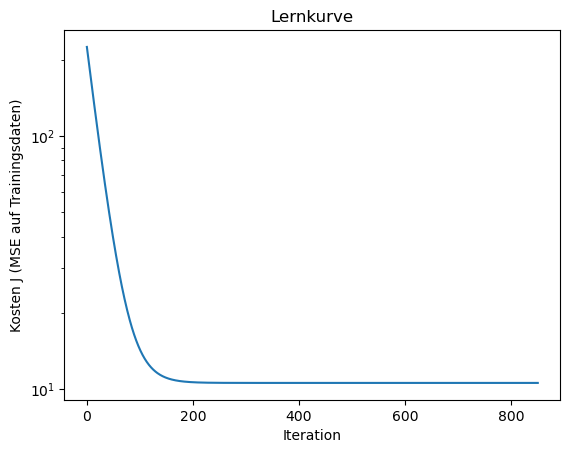

In [11]:
plt.plot(model.cost_history)
plt.xlabel("Iteration")
plt.ylabel("Kosten J (MSE auf Trainingsdaten)")
plt.title("Lernkurve")
plt.yscale("log")
plt.show()

Und so sieht die gelernte Regressionsgerade aus (Folie 8). Für die Darstellung rechnen wir die Gerade wieder in die Originaleinheit des TV-Budgets um:

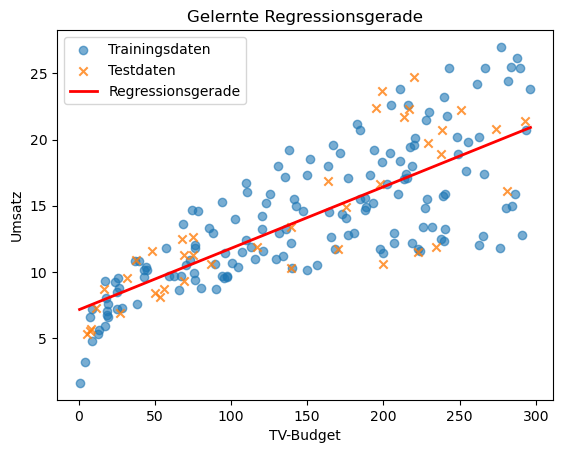

In [12]:
x_line = np.linspace(x.min(), x.max(), 100)
y_line = model.predict((x_line - mu) / sigma)

plt.scatter(x_train, y_train, alpha=0.6, label="Trainingsdaten")
plt.scatter(x_test, y_test, alpha=0.8, marker="x", label="Testdaten")
plt.plot(x_line, y_line, color="red", lw=2, label="Regressionsgerade")
plt.xlabel("TV-Budget"); plt.ylabel("Umsatz")
plt.legend(); plt.title("Gelernte Regressionsgerade")
plt.show()

---
# Teil 2: Evaluation, Lernrate und Vergleich mit sklearn

## 2.1 Evaluation auf den Testdaten

Wie gut ist das Modell auf **ungesehenen** Daten (Folie 37/38)? Wir berechnen für jeden Testpunkt die Vorhersage $\hat{y}_i$ und den Fehler $e_i = y_i - \hat{y}_i$, und daraus:

$$\text{MSE} = \frac{1}{n}\sum_{i=1}^{n} e_i^2 \qquad \text{MAE} = \frac{1}{n}\sum_{i=1}^{n} |e_i|$$

In [13]:
def mae(y, y_pred):
    # Mean Absolute Error
    return np.mean(np.abs(y - y_pred))

y_pred_test = model.predict(x_test_s)
mse_1 = mse(y_test, y_pred_test)

print(f"Test-MSE: {mse_1:.3f}")
print(f"Test-MAE: {mae(y_test, y_pred_test):.3f}   (im Schnitt liegen wir so viele Umsatz-Einheiten daneben)")

Test-MSE: 10.205
Test-MAE: 2.444   (im Schnitt liegen wir so viele Umsatz-Einheiten daneben)


## 2.2 Einfluss der Lernrate

Die Lernrate $\alpha$ bestimmt die Schrittgröße (Folie 33). Vergleichen wir mehrere Werte:

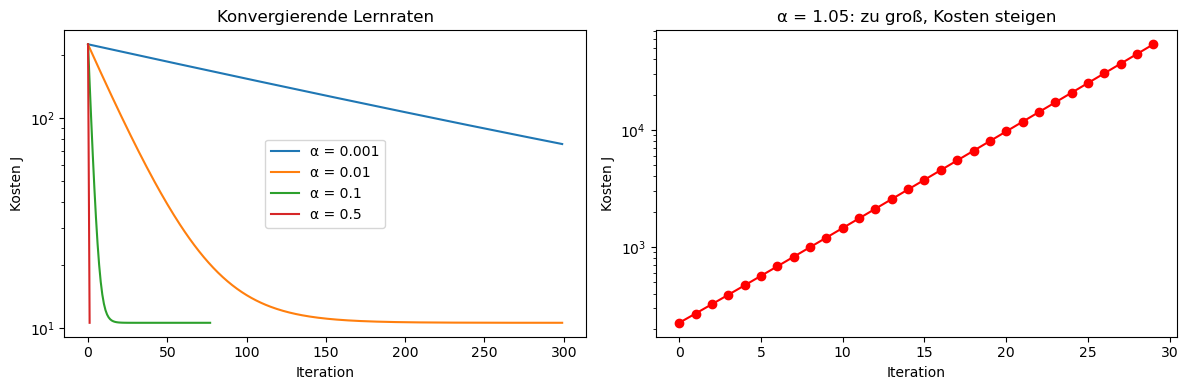

In [14]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

for lr in [0.001, 0.01, 0.1, 0.5]:
    m = SimpleLinearRegressionGD(learning_rate=lr, max_iterations=300).fit(x_train_s, y_train)
    axes[0].plot(m.cost_history, label=f"α = {lr}")
axes[0].set_yscale("log"); axes[0].set_xlabel("Iteration"); axes[0].set_ylabel("Kosten J")
axes[0].set_title("Konvergierende Lernraten"); axes[0].legend()

with np.errstate(over="ignore", invalid="ignore"):
    m = SimpleLinearRegressionGD(learning_rate=1.05, max_iterations=30).fit(x_train_s, y_train)
axes[1].plot(m.cost_history, color="red", marker="o")
axes[1].set_yscale("log"); axes[1].set_xlabel("Iteration"); axes[1].set_ylabel("Kosten J")
axes[1].set_title("α = 1.05: zu groß, Kosten steigen")

plt.tight_layout(); plt.show()

- **Zu kleine Lernrate** (0.001): sehr langsame Annäherung an das Minimum.
- **Passende Lernrate** (0.01 – 0.5): schnelle Konvergenz.
- **Zu große Lernrate** (1.05): Gradient Descent springt über das Minimum hinaus, die Kosten **steigen**.

## 2.3 Vergleich mit sklearn

In der Praxis nutzt man `sklearn.linear_model.LinearRegression` (Folie 34). sklearn verwendet intern kein Gradient Descent, sondern löst die Normalgleichung direkt – sollte aber dieselben Gewichte finden:

In [15]:
from sklearn.linear_model import LinearRegression

sk_model = LinearRegression().fit(x_train_s.reshape(-1, 1), y_train)   # sklearn erwartet 2D-Input

print(f"Unser Modell: w0 = {model.w0:.4f}, w1 = {model.w1:.4f}")
print(f"sklearn:      w0 = {sk_model.intercept_:.4f}, w1 = {sk_model.coef_[0]:.4f}")

Unser Modell: w0 = 14.1000, w1 = 3.9157
sklearn:      w0 = 14.1000, w1 = 3.9157


---
# Teil 3: Mehrere Features

## 3.1 Modell in Vektorschreibweise

Mit $d$ Features lautet das Modell (Folie 45):

$$f_{\mathbf{w}}(\mathbf{x}) = w_0 + w_1 x_1 + \dots + w_d x_d = w_0 + \sum_{j=1}^{d} w_j x_j$$

Die Kostenfunktion bleibt der MSE, und Gradient Descent funktioniert genauso – nur aktualisieren wir jetzt alle Gewichte $w_0, \dots, w_d$ in einer Iteration (Folie 46).

Für jedes Gewicht $w_j$ ($j \geq 1$) lautet der Gradient:

$$\frac{\partial J}{\partial w_j} = \frac{1}{n}\sum_{i=1}^{n} -2\,x_{ij}\,(y_i - \hat{y}_i)$$

Statt einer Schleife über alle $j$ berechnen wir alle Gradienten auf einmal mit einer Matrixmultiplikation. Die Datenmatrix $X$ hat $n$ Zeilen (Datenpunkte) und $d$ Spalten (Features):

- `X @ w` berechnet $\sum_j w_j x_{ij}$ für alle Datenpunkte gleichzeitig,
- `X.T @ error` berechnet $\sum_i x_{ij}\,e_i$ für alle Features gleichzeitig.

In [16]:
class LinearRegressionGD:
    # Lineare Regression mit beliebig vielen Features, trainiert mit Gradient Descent

    def __init__(self, learning_rate=0.01, max_iterations=5000, tolerance=1e-6):
        self.learning_rate = learning_rate
        self.max_iterations = max_iterations
        self.tolerance = tolerance

    def predict(self, X):
        return self.w0 + X @ self.w

    def fit(self, X, y):
        X = np.atleast_2d(X)
        n, d = X.shape

        # Zufällige Startwerte für w0 und w1, ..., wd
        self.w0 = np.random.randn() * 0.01
        self.w = np.random.randn(d) * 0.01
        self.cost_history = []

        for iteration in range(self.max_iterations):
            error = y - self.predict(X)                  # e_i für alle Datenpunkte
            self.cost_history.append(np.mean(error ** 2))

            # Alle Gradienten mit den alten Gewichten berechnen ...
            grad_w0 = -2 * np.mean(error)
            grad_w = -2 * (X.T @ error) / n              # Vektor mit d Einträgen

            # ... und dann alle Gewichte gleichzeitig aktualisieren
            self.w0 -= self.learning_rate * grad_w0
            self.w -= self.learning_rate * grad_w

            if abs(grad_w0) < self.tolerance and np.linalg.norm(grad_w) < self.tolerance:
                break

        self.n_iterations = iteration + 1
        return self

## 3.2 Training mit TV-, Radio- und Zeitungsbudget

Wie in Folie 41 nehmen wir jetzt alle drei Werbebudgets als Features. Wichtig ist wieder: erst splitten, dann mit den Kennzahlen der Trainingsdaten standardisieren – jetzt für jede Spalte einzeln.

In [17]:
features = ["TV", "radio", "newspaper"]
X = df[features].values
y = df["sales"].values

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

mu, sigma = X_train.mean(axis=0), X_train.std(axis=0)    # pro Feature
X_train_s = (X_train - mu) / sigma
X_test_s = (X_test - mu) / sigma

model_multi = LinearRegressionGD(learning_rate=0.01).fit(X_train_s, y_train)

print(f"Konvergiert nach {model_multi.n_iterations} Iterationen")
print(f"w0 = {model_multi.w0:.4f}")
for name, w in zip(features, model_multi.w):
    print(f"  Gewicht {name:<10} = {w:.4f}")

Konvergiert nach 1186 Iterationen
w0 = 14.1000
  Gewicht TV         = 3.7642
  Gewicht radio      = 2.7923
  Gewicht newspaper  = 0.0560


In [18]:
y_pred_test = model_multi.predict(X_test_s)
mse_3 = mse(y_test, y_pred_test)

print(f"Test-MSE mit 1 Feature (TV):            {mse_1:.3f}")
print(f"Test-MSE mit 3 Features (TV, Radio, Zeitung): {mse_3:.3f}")
print(f"Test-MAE mit 3 Features:                {mae(y_test, y_pred_test):.3f}")

Test-MSE mit 1 Feature (TV):            10.205
Test-MSE mit 3 Features (TV, Radio, Zeitung): 3.174
Test-MAE mit 3 Features:                1.461


Mit drei Features sinkt der Testfehler deutlich: Das Radio-Budget enthält offenbar Information, die das TV-Budget allein nicht liefert.

Bei mehreren Features können wir die Regressionsebene nicht mehr zeichnen. Stattdessen vergleichen wir echte Werte und Vorhersagen – liegen die Punkte nahe an der Diagonalen, sind die Vorhersagen gut:

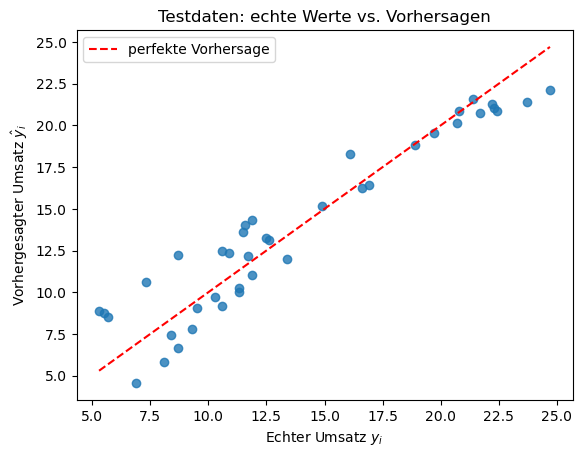

In [19]:
plt.scatter(y_test, y_pred_test, alpha=0.8)
lims = [y_test.min(), y_test.max()]
plt.plot(lims, lims, "r--", label="perfekte Vorhersage")
plt.xlabel("Echter Umsatz $y_i$"); plt.ylabel("Vorhergesagter Umsatz $\\hat{y}_i$")
plt.title("Testdaten: echte Werte vs. Vorhersagen")
plt.legend(); plt.show()

## 3.3 Feature Importance

Bei linearer Regression kann man die Wichtigkeit eines Features am **Betrag seines Gewichts** ablesen (Folie 47/48) – aber **nur, wenn alle Features gleich skaliert sind**.

Vergleichen wir die Gewichte unseres Modells (standardisierte Features) mit einem Modell auf den Rohdaten:

In [20]:
sk_raw = LinearRegression().fit(X_train, y_train)    # Rohdaten, nicht standardisiert

comparison = pd.DataFrame({
    "Gewicht (Rohdaten)": sk_raw.coef_,
    "Gewicht (standardisiert)": model_multi.w,
    "Std.-Abw. des Features": sigma,
}, index=features)
comparison.round(4)

,Gewicht (Rohdaten),Gewicht (standardisiert),Std.-Abw. des Features
TV,0.0447,3.7642,84.1546
radio,0.1892,2.7923,14.7589
newspaper,0.0028,0.0560,20.2728


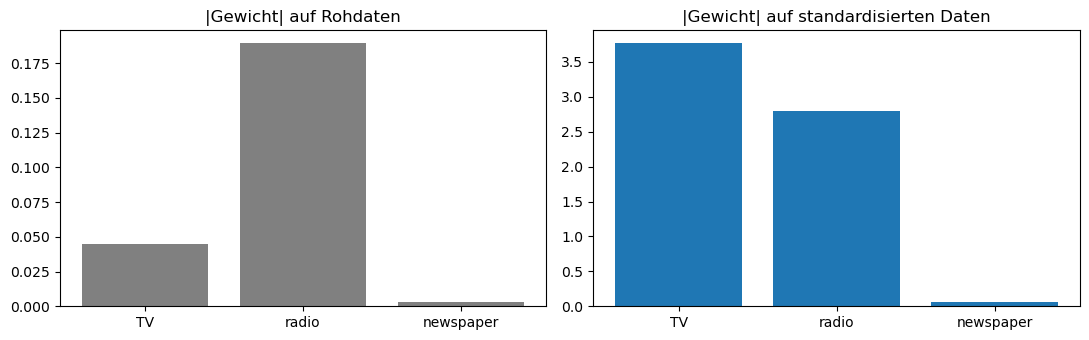

In [21]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.5))
axes[0].bar(features, np.abs(sk_raw.coef_), color="gray")
axes[0].set_title("|Gewicht| auf Rohdaten")
axes[1].bar(features, np.abs(model_multi.w), color="tab:blue")
axes[1].set_title("|Gewicht| auf standardisierten Daten")
plt.tight_layout(); plt.show()

**Die Rangfolge dreht sich!**

- Auf den **Rohdaten** hat Radio das größte Gewicht. Das liegt aber nur daran, dass das Radio-Budget viel weniger streut als das TV-Budget: Ein Gewicht gibt an, wie stark sich der Umsatz pro **Einheit** des Features ändert – und eine Einheit Radio-Budget ist relativ zur typischen Spannweite viel mehr als eine Einheit TV-Budget.
- Auf den **standardisierten** Daten gibt jedes Gewicht an, wie stark sich der Umsatz ändert, wenn das Feature um **eine Standardabweichung** steigt. Jetzt sind die Gewichte vergleichbar: **TV ist das wichtigste Feature**, Radio das zweitwichtigste, Zeitung ist unbedeutend.

> **Merke:** Gewichte nur auf gleich skalierten (z. B. standardisierten) Features als Feature Importance interpretieren.

## 3.4 Vergleich mit sklearn

In [22]:
sk_multi = LinearRegression().fit(X_train_s, y_train)

print(f"Unser Modell: w0 = {model_multi.w0:.4f}, w = {np.round(model_multi.w, 4)}")
print(f"sklearn:      w0 = {sk_multi.intercept_:.4f}, w = {np.round(sk_multi.coef_, 4)}")

Unser Modell: w0 = 14.1000, w = [3.7642 2.7923 0.056 ]
sklearn:      w0 = 14.1000, w = [3.7642 2.7923 0.056 ]
